# Прогнозирование остаточного ресурса и детектор деградации (NASA CMAPSS)

Пет-проект: система предиктивного обслуживания авиадвигателя по телеметрии.
Два компонента: регрессия остаточного ресурса (RUL, «сколько циклов осталось»)
и детектор начала деградации («началась ли деградация»). Четыре набора данных
(FD001–FD004), все выводы — на данных, которых компоненты не видели при
разработке, или на групповой кросс-валидации.

Код: github.com/DadyaD/data_science

## Содержание

1. FD001: EDA, модель RUL, детектор деградации (главы 1–4)
2. FD003: перенос на другой тип отказа (глава 5)
3. FD002: рабочие режимы, z-нормировка, детектор v2 (глава 6)
4. FD004: смешанные отказы, маршрутизатор типов (глава 7)

## Итоговые результаты

| Набор | Модель: native CV | Модель: transfer | Детектор strict | Ложные тревоги |
|---|---|---|---|---|
| FD001 (1 режим, КВД) | 18.70 | — | 98% | 1.6% |
| FD002 (6 режимов, КВД) | 19.85 (z: 19.62) | 49.83 ← из FD001 | 91% | 4.1% |
| FD003 (1 режим, вентилятор) | — | 26.43 ← из FD001 | 89% | 18.6% |
| FD004 (6 режимов, смешанные) | 17.93 | 35.25 ← из FD002 | 90% | 7.7% |

In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
pd.set_option('display.max_columns', 30)

In [ ]:
CONFIG = dict(first_n=30, k=5, sustain=5, clip=125, n_thr_levels = 2,
              std_thresh=0.01, random_state=42)

In [ ]:
# названия колонок по документации NASA
cols = ['engine_id', 'cycle'] + \
       [f'os_{i}' for i in range(1, 4)] + \
       [f'sensor_{i}' for i in range(1, 22)]


In [ ]:
train = pd.read_csv('train_FD001.txt', sep=r'\s+', header=None, names=cols)
test  = pd.read_csv('test_FD001.txt',  sep=r'\s+', header=None, names=cols)
rul_test = pd.read_csv('RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL_true'])

## Глава 1. Загрузка и первый осмотр (FD001)

Данные NASA CMAPSS, поднабор FD001: 100 обучающих и 100 тестовых двигателей,
21 сенсор + 3 режимных параметра, один тип отказа (деградация компрессора
высокого давления). В train запись каждого двигателя обрывается в момент
отказа — это позволит построить таргет. В test запись обрывается до отказа,
истинный остаток ресурса — в отдельном файле (закрытая тестовая метка).

In [ ]:
print(f'train: {train.shape}')
print(f'test:  {test.shape}')
train.head()

train: (20631, 26)
test:  (13096, 26)


,engine_id,cycle,os_1,os_2,os_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Глава 2. EDA: как выглядит деградация

Вопрос: у каких каналов телеметрии виден тренд к отказу? Строим траектории
первых двигателей. Побочная находка: sensor_9 (~9000 об/мин) — физическая
частота вращения ротора, опознана по характеру значений до чтения
документации.

In [ ]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
os_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
os_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
os_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


Каналы со стандартным отклонением < 0.01 не несут сигнала о деградации:
условия симуляции держат их постоянными. Важно: список констант
пересчитывается для каждого набора отдельно — в других поднаборах (FD002–004)
он другой.

Построим графики сенсоров, которые имеют не нулевое стандартное отклонение

In [ ]:
zero_std = train.std(numeric_only=True)
zero_cols = zero_std[zero_std == 0].index.tolist()
print('Константные:', zero_cols)

sensors = [c for c in train.columns
           if c.startswith('sensor') and c not in zero_cols]
print(f'Анализируем {len(sensors)} сенсоров')

Константные: ['os_3', 'sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']
Анализируем 17 сенсоров


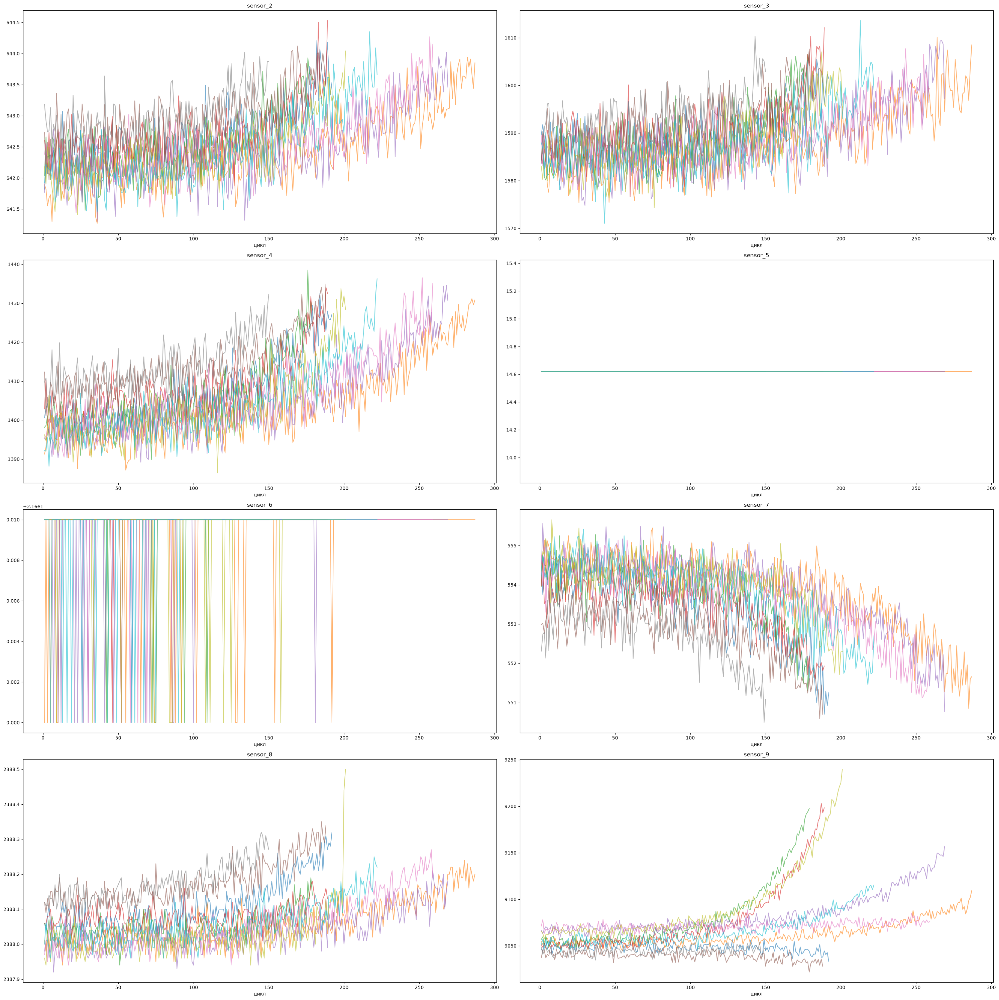

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(30, 30))
sensors_to_plot = sensors 
for ax, s in zip(axes.flat, sensors_to_plot):
    for eng in train['engine_id'].unique()[:10]:   # первые 10 двигателей
        df = train[train['engine_id'] == eng]
        ax.plot(df['cycle'], df[s], alpha=0.6)
    ax.set_title(s)
    ax.set_xlabel('цикл')

plt.tight_layout()
plt.show()

Ресурс двигателей до отказа

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


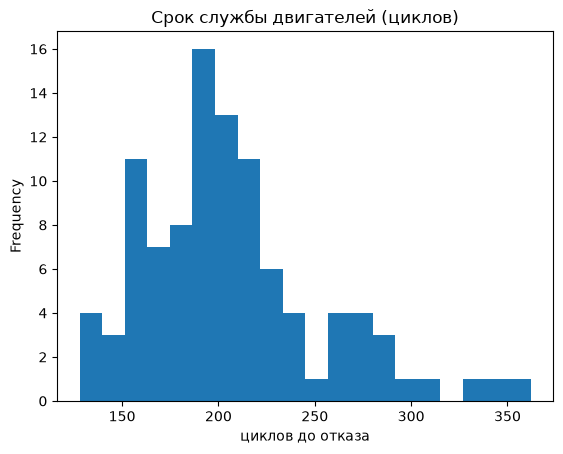

In [ ]:
lifetimes = train.groupby('engine_id')['cycle'].max()
print(lifetimes.describe())

lifetimes.plot.hist(bins=20, title='Срок службы двигателей (циклов)')
plt.xlabel('циклов до отказа')
plt.show()

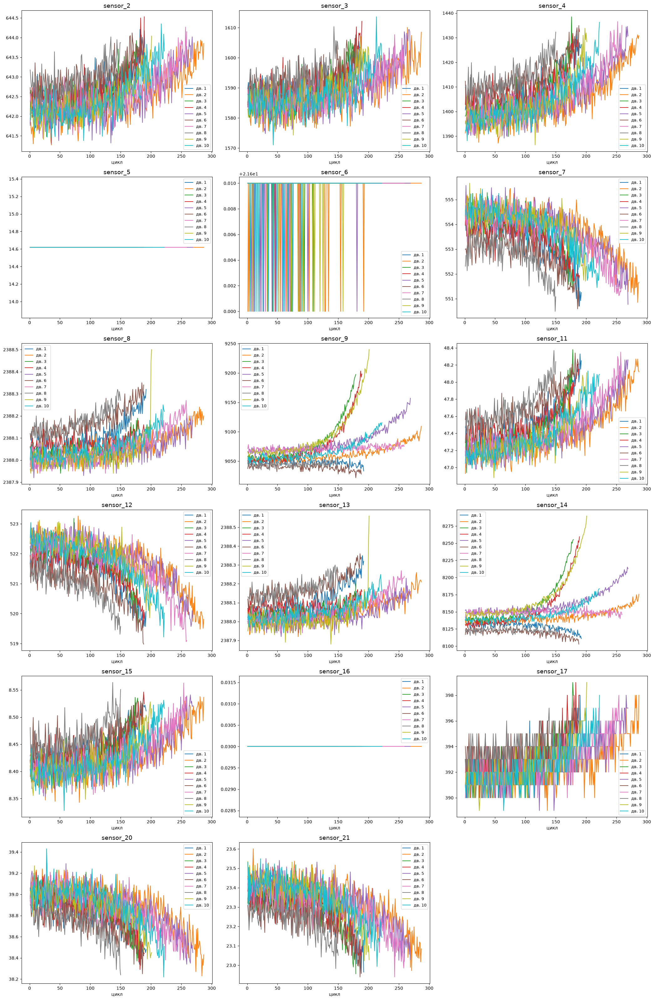

In [ ]:
engines = sorted(train['engine_id'].unique())[:10]   # двигатели 1–10
sub = train[train['engine_id'].isin(engines)]

fig, axes = plt.subplots(6, 3, figsize=(21, 32))     # 17 сенсоров → 18 ячеек
for ax, s in zip(axes.flat, sensors):
    for eng in engines:
        df = sub[sub['engine_id'] == eng]
        ax.plot(df['cycle'], df[s], label=f'дв. {eng}')
    ax.set_title(s, fontsize=14)
    ax.set_xlabel('цикл')
    ax.legend(fontsize=9)

axes.flat[-1].axis('off')   # последняя ячейка пустая — выключаем
plt.tight_layout()
plt.show()

Видно, что 5, 6, 16 сенсор тоже константа и не несут полезной информации. Когда мы просматривали информацию по данным можно было увидеть, что стандартное отклонение очень мало везде, но из графиков видноБ что при 10 в -3 степени значения неинформативныБ отбросим их

In [ ]:
# константные колонки: разброс меньше 0.01
const_cols = zero_std[zero_std < 0.01].index.tolist()

# рабочие сенсоры: всё, что не константа
sensors = [c for c in train.columns
           if c.startswith('sensor') and c not in const_cols]

train_clean = train.drop(columns=const_cols)   # датасет без мусорных колонок
test_clean = test.drop(columns=const_cols)    


## Таргет: остаточный ресурс (RUL)

В train запись каждого двигателя обрывается в момент отказа, поэтому
RUL = (макс. цикл − текущий). Клип сверху 125 — кусочно-линейная модель
деградации NASA: раньше 125 циклов до отказа двигатель считается здоровым.

In [ ]:
max_cycle = train_clean.groupby('engine_id')['cycle'].transform('max')
train_clean['RUL'] = (max_cycle - train_clean['cycle']).clip(upper=CONFIG['clip'])
train_clean[['engine_id', 'cycle', 'RUL']].head(15)

,engine_id,cycle,RUL
0,1,1,125
1,1,2,125
2,1,3,125
3,1,4,125
4,1,5,125
5,1,6,125
6,1,7,125
7,1,8,125
8,1,9,125
9,1,10,125


## Глава 4. Модель RUL

Линейная регрессия на сырых сенсорах — точка отсчёта, которую обязана
побить любая сложная модель.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

features = [c for c in train_clean.columns if c.startswith('sensor') or c.startswith('os')]

X_train, y_train = train_clean[features], train_clean['RUL']

# для теста: берём показания ПОСЛЕДНЕГО цикла каждого двигателя
X_test = test_clean.groupby('engine_id')[features].last().values
y_test = rul_test['RUL_true']

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
print('Baseline RMSE:', np.sqrt(mean_squared_error(y_test, pred)))

Baseline RMSE: 21.90021340689122


/Applications/anaconda/miniconda3/envs/ds/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


RMSE: 21.9

Проверяем гипотезу: помогут ли признаки (rolling-признаки — скользящие
средние и отклонения от них)? Ожидание: да, деградация — процесс во времени.

## Градиентный бустинг: сырые сенсоры vs rolling-признаки

In [ ]:
import lightgbm as lgb
from sklearn.metrics import mean_squared_error

In [ ]:
def add_features(df, sens, window=5):
    df = df.sort_values(['engine_id', 'cycle']).copy()
    parts = []
    for eng, g in df.groupby('engine_id'):   # идём по двигателям
        g = g.copy()
        for s in sens:                    # внутри — по сенсорам
            ma = g[s].rolling(window, min_periods=1).mean()  # скользящее среднее
            g[f'{s}_ma{window}'] = ma
            g[f'{s}_dev{window}'] = g[s] - ma
        parts.append(g)
    return pd.concat(parts)                  # собираем всё обратно в один датафрейм

In [ ]:
sens = [c for c in train_clean.columns
           if c.startswith('sensor')]
W = 5
train_f = add_features(train_clean, sens, W)
test_f  = add_features(test_clean, sens, W)

features = [c for c in train_f.columns
            if c.startswith('sensor') and c not in ('engine_id', 'cycle')]

X_train, y_train = train_f[features], train_f['RUL']
X_test = test_f.groupby('engine_id')[features].last()
y_test = rul_test['RUL_true']

import lightgbm as lgb
from sklearn.metrics import mean_squared_error

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05,
                          num_leaves=31, random_state=CONFIG['random_state'], verbose=-1)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print('LightGBM RMSE:', np.sqrt(mean_squared_error(y_test, pred)))

LightGBM RMSE: 18.294657436187542


так же я проверил здесь RMSE при zero_std < 0.01. Данные не изменились, так что признаки приняты в шум правильно

Проверим что получилось бы, используй мы лишь lghtlbm

In [ ]:
raw_features = sens

X_train_raw = train[raw_features]
X_test_raw = test.groupby('engine_id')[raw_features].last()

model_raw = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05,
                              num_leaves=31, random_state=CONFIG['random_state'], verbose=-1)
model_raw.fit(X_train_raw, y_train)
pred_raw = model_raw.predict(X_test_raw)
print('LightGBM на сырых сенсорах RMSE:',
      np.sqrt(mean_squared_error(y_test, pred_raw)))

LightGBM на сырых сенсорах RMSE: 17.813753995069835


**Негативный результат:** rolling-признаки не улучшили бустинг
(18.29 против 17.81 на сырых сенсорах). Гипотеза: деревья сами извлекают
нелинейные зависимости, а на выборке из 100 двигателей дополнительные
признаки вносят шум. В финальной модели не используем.

проверим отличается ли результат, если взять данные ближе к отказу

In [ ]:
err = pd.Series(pred - y_test)
print('RMSE при RUL<50:',
      np.sqrt(np.mean(err[y_test < 50] ** 2)))

RMSE при RUL<50: 14.076140490744729


Проверим насколько это отличается от наивного прогноза 

In [ ]:
# константа = средний RUL обучающих двигателей в той же зоне (по train)
zone_mean = train_f.loc[train_f['RUL'] < 50, 'RUL'].mean()
mask = y_test < 50
base = pd.Series(zone_mean, index=y_test.index)
print('baseline (среднее train в зоне):',
      np.sqrt(np.mean((base[mask] - y_test[mask]) ** 2)),
      f'(константа = {zone_mean:.1f})')

baseline (среднее train в зоне): 11.5 (константа = 24.5)


Ближе к концу цикла тоже смысла брать нет, результат получается не точнее наивного прогноза

Для избежания некоректных показателей работы нашей модели, добавим кросс-валидацию данных, что бы избежать подгонки результатов при проверке на тестовой выборке. 

## Честная валидация

Test мал (100 двигателей), а экспериментов много — подбор по test дал бы
скрытую подгонку. Вводим GroupKFold с группировкой по двигателям
(строки одного агрегата коррелированы — случайное разбиение дало бы
утечку) и GridSearchCV с параметрами, зафиксированными заранее.

In [ ]:
from sklearn.model_selection import GridSearchCV, GroupKFold

param_grid = {
    'n_estimators': [300, 500, 800],
    'learning_rate': [0.03, 0.05],
    'num_leaves': [31, 63],
}

gkf = GroupKFold(n_splits=5)

grid = GridSearchCV(
    estimator=lgb.LGBMRegressor(random_state=CONFIG['random_state'], verbose=-1),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=gkf,
    n_jobs=-1,
)

grid.fit(train_clean[sens], train_clean['RUL'],
         groups=train_clean['engine_id'])
print('Лучшие параметры:', grid.best_params_)
print(f'Лучший CV RMSE: {-grid.best_score_:.2f}')

Лучшие параметры: {'learning_rate': 0.03, 'n_estimators': 300, 'num_leaves': 31}
Лучший CV RMSE: 18.69


Лучшие параметры: {'learning_rate': 0.03, 'n_estimators': 300, 'num_leaves': 31}
Лучший CV RMSE: 18.70

Это на предобработанных данных

Проверим все предидущие методы вместе

Переберем циклом варианты окон скользящего среднего

**Архив, не запускать.** Перебор окон rolling-признаков (W = 5, 10, 15,
GridSearchCV × GroupKFold): CV RMSE 18.70–18.72 — статистически не
отличается от сырых сенсоров (18.70). Вывод зафиксирован: rolling-признаки
в финальную модель не входят. Код хранится в истории git.

In [ ]:
# from sklearn.model_selection import GridSearchCV, GroupKFold

# param_grid = {
#     'n_estimators': [300, 500],
#     'learning_rate': [0.02, 0.025, 0.03],
#     'num_leaves': [25, 55],
# }

# gkf = GroupKFold(n_splits=5)

# results = {}
# for W in [5, 10, 15]:
#     # для каждого окна — своя версия признаков
#     train_f = add_features(train_clean, sens, W)
#     feats = [c for c in train_f.columns
#              if c.startswith('sensor') and c not in ('engine_id', 'cycle')]

#     grid = GridSearchCV(
#         estimator=lgb.LGBMRegressor(random_state=CONFIG['random_state'], verbose=-1),
#         param_grid=param_grid,
#         scoring='neg_root_mean_squared_error',
#         cv=gkf,
#         n_jobs=-1,
#     )
#     grid.fit(train_f[feats], train_f['RUL'],
#              groups=train_f['engine_id'])

#     results[W] = grid
#     print(f'W={W}: CV RMSE {-grid.best_score_:.2f} | '
#           f'{grid.best_params_}')

Лучшие параметры:W=5 CV RMSE 18.42 | {'learning_rate': 0.02, 'n_estimators': 300, 'num_leaves': 25}
Как и ранее, изменения при использовании скользящего среднего не наблюдаются. 

Конфигурация выбрана по CV → обучение на всём train → **один** прогон на
test. После этого тест закрыт: любые итерации по нему делали бы оценку
нечестной.

In [ ]:
final_model = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                                num_leaves=31, random_state=CONFIG['random_state'], verbose=-1)
final_model.fit(train_clean[sensors], train_clean['RUL'])

# ОДИН прогон на test — после него test закрыт
X_test = test_clean.groupby('engine_id')[sensors].last()
pred = final_model.predict(X_test)
print('Финальный test RMSE:',
      np.sqrt(mean_squared_error(y_test, pred)))

Финальный test RMSE: 17.924388412484642


Финальный test RMSE: 17.924388412484642

In [ ]:
import joblib
joblib.dump(final_model, 'model_rul_fd001.pkl')

['model_rul_fd001.pkl']

## Детектор начала деградации

Смежная задача: не «сколько осталось», а «началась ли деградация».
Строим правило итеративно; на каждом шаге проверяем не только запас
предупреждения, но и ложные тревоги в здоровой зоне (RUL > 125, цикл > 30).
Одна маска для всех версий.

Определим в каких сенсорах присутствуют выбросы

In [ ]:
outlier_cols = []
for s in sens:
    mu = train_clean[s].mean()
    sd = train_clean[s].std()
    col = f'{s}_out'
    train_clean[col] = (train_clean[s] - mu).abs() > 2 * sd
    outlier_cols.append(col)

Создадим таблицу сгруппированную по двигателям, со сроком жизни с начала выбросов

In [ ]:
rows = []
for eng, g in train_clean.groupby('engine_id'):
    has_out = g[outlier_cols].any(axis=1)
    if has_out.any():
        first_out = g.loc[has_out, 'cycle'].min()
        lifetime = g['cycle'].max()
        rows.append((eng, first_out, lifetime, lifetime - first_out))

out_tab = pd.DataFrame(rows, columns=['engine', 'first_out_cycle',
                                      'lifetime', 'cycles_out_to_fail'])
print(out_tab.head())
print()
print(out_tab['cycles_out_to_fail'].describe())

   engine  first_out_cycle  lifetime  cycles_out_to_fail
0       1                3       192                 189
1       2                1       287                 286
2       3                2       179                 177
3       4               11       189                 178
4       5                2       269                 267

count    100.000000
mean     172.500000
std       70.990183
min       28.000000
25%      139.750000
50%      177.500000
75%      211.250000
max      360.000000
Name: cycles_out_to_fail, dtype: float64


Как видим, таблица неинформативна, выбросы начинаются на первых циклах. Это возможно, но кратковременно. Увеличим постояннство выбросов до трех срабатываний подряд

In [ ]:
outlier_cols = []
for s in sens:
    mu = train_clean[s].mean()
    sd = train_clean[s].std()
    col = f'{s}_out'
    train_clean[col] = (train_clean[s] - mu).abs() > 2 * sd
    train_clean[col] = train_clean.groupby('engine_id')[col].transform(
    lambda x: x.rolling(3).sum() >= 3)
    outlier_cols.append(col)

Еще раз построим таблицу

In [ ]:
rows = []
for eng, g in train_clean.groupby('engine_id'):
    has_out = g[outlier_cols].any(axis=1)
    if has_out.any():
        first_out = g.loc[has_out, 'cycle'].min()
        lifetime = g['cycle'].max()
        rows.append((eng, first_out, lifetime, lifetime - first_out))

out_tab = pd.DataFrame(rows, columns=['engine', 'first_out_cycle',
                                      'lifetime', 'cycles_out_to_fail'])
print(out_tab.head())
print()
print(out_tab['cycles_out_to_fail'].describe())

   engine  first_out_cycle  lifetime  cycles_out_to_fail
0       1              186       192                   6
1       2               57       287                 230
2       3              151       179                  28
3       4              159       189                  30
4       5               30       269                 239

count    100.000000
mean      33.480000
std       54.117993
min        1.000000
25%       10.000000
50%       16.500000
75%       28.000000
max      279.000000
Name: cycles_out_to_fail, dtype: float64


**Версия A: парковый эталон.** Коридор нормы — по всем двигателям сразу.
Результат: чисто (ложных тревог мало), но поздно — медианный запас
16.5 цикла. Причина: деградация «размывает» парковый коридор.

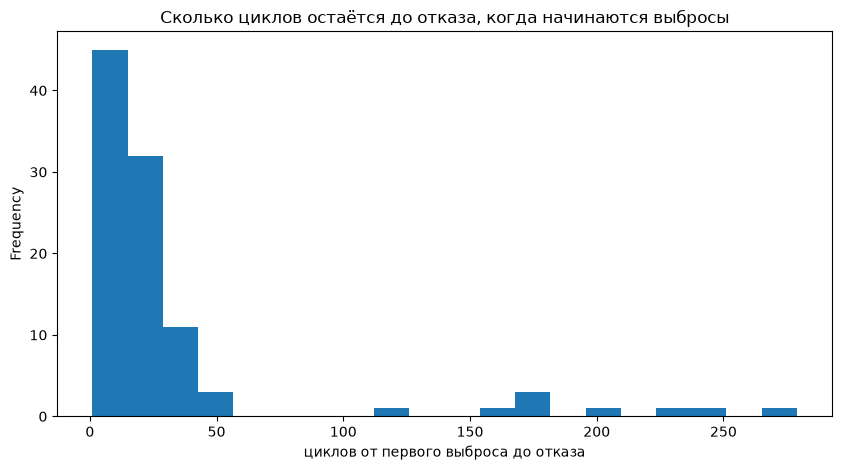

In [ ]:
out_tab['cycles_out_to_fail'].plot.hist(bins=20, figsize=(10, 5),
    title='Сколько циклов остаётся до отказа, когда начинаются выбросы')
plt.xlabel('циклов от первого выброса до отказа')
plt.show()

Попробуем посмотреть наш метод на заранее здоровых двигателях

In [ ]:
# эталон «здоровья»: строки, где RUL > 100 (двигатель точно в начале жизни)
healthy = train_clean[train_clean['RUL'] > 100]

outlier_cols_b = []
for s in sensors:
    mu = healthy[s].mean()
    sd = healthy[s].std()
    col = f'{s}_outB'
    train_clean[col] = (train_clean[s] - mu).abs() > 2 * sd
    outlier_cols_b.append(col)

In [ ]:
rows = []
for eng, g in train_clean.groupby('engine_id'):
    has_out = g[outlier_cols_b].any(axis=1)
    if has_out.any():
        first_out = g.loc[has_out, 'cycle'].min()
        lifetime = g['cycle'].max()
        rows.append((eng, first_out, lifetime, lifetime - first_out))

out_tab = pd.DataFrame(rows, columns=['engine', 'first_out_cycle',
                                      'lifetime', 'cycles_out_to_fail'])
print(out_tab.head())
print()
print(out_tab['cycles_out_to_fail'].describe())

   engine  first_out_cycle  lifetime  cycles_out_to_fail
0       1                3       192                 189
1       2                1       287                 286
2       3                2       179                 177
3       4               11       189                 178
4       5                2       269                 267

count    100.000000
mean     202.920000
std       46.857765
min      126.000000
25%      171.750000
50%      194.000000
75%      223.250000
max      360.000000
Name: cycles_out_to_fail, dtype: float64


**Версия B (эталон по здоровой зоне):** тревожит всех с первых циклов —
ловит индивидуальность агрегатов, а не деградацию.

Попробуем объединить методы, построим первый метод для двигателя определяющего эталон работы по самому себе

In [ ]:
FIRST_N = 30   # эталонная «здоровая» часть жизни каждого двигателя

outlier_cols_c = []
for s in sensors:
    col = f'{s}_outC'
    train_clean[col] = False
    for eng, g in train_clean.groupby('engine_id'):
        base = g.loc[g['cycle'] <= FIRST_N, s]
        mu = base.mean()
        sd = base.std()
        if sd < 1e-6:                      # эталон выродился — берём глобальный σ
            sd = train_clean[s].std()
        idx = g.index[g['cycle'] > FIRST_N]
        train_clean.loc[idx, col] = ((g.loc[idx, s] - mu).abs() > 2 * sd)
    outlier_cols_c.append(col)

In [ ]:
rows = []
for eng, g in train_clean.groupby('engine_id'):
    has_out = g[outlier_cols_c].any(axis=1)
    if has_out.any():
        first_out = g.loc[has_out, 'cycle'].min()
        lifetime = g['cycle'].max()
        rows.append((eng, first_out, lifetime, lifetime - first_out))

out_tab = pd.DataFrame(rows, columns=['engine', 'first_out_cycle',
                                      'lifetime', 'cycles_out_to_fail'])
print(out_tab.head())
print()
print(out_tab['cycles_out_to_fail'].describe())

   engine  first_out_cycle  lifetime  cycles_out_to_fail
0       1               31       192                 161
1       2               31       287                 256
2       3               31       179                 148
3       4               32       189                 157
4       5               31       269                 238

count    100.000000
mean     174.480000
std       46.334637
min       97.000000
25%      145.500000
50%      167.000000
75%      198.000000
max      331.000000
Name: cycles_out_to_fail, dtype: float64


**Версия C: персональный эталон** (первые 30 циклов каждого двигателя).
Идея верная — но две реализационные ошибки подряд: флаги считались и внутри
калибровочного окна (детектор тестировался на собственной калибровке,
гарантированные ложные срабатывания) и коридор из 30 точек оказался
слишком узким (тревога строго по протоколу, на 31-м цикле, вне зависимости
от состояния).

Проверим  метод не 3-х срабатываний подряд, а то, что скользящее среднее постоянно росло или убывало

In [ ]:
FIRST_N = 30
K = 5          # окно сглаживания
SUSTAIN = 5    # сколько циклов дрейф должен держаться

trend_cols = []
for s in sens:
    col = f'{s}_trend'
    train_clean[col] = False
    for eng, g in train_clean.groupby('engine_id'):
        base = g.loc[g['cycle'] <= FIRST_N, s]
        mu = base.mean()
        sd = base.std()
        if sd < 1e-6:
            sd = train_clean[s].std()
        idx = g.index[g['cycle'] > FIRST_N]
        ma = g.loc[idx, s].rolling(K, min_periods=1).mean()
        drift = (ma - mu).abs() > 2 * sd
        train_clean.loc[idx, col] = (drift.rolling(SUSTAIN).sum() >= SUSTAIN).values
    trend_cols.append(col)

In [ ]:
rows = []
for eng, g in train_clean.groupby('engine_id'):
    has_out = g[trend_cols].any(axis=1)
    if has_out.any():
        first_out = g.loc[has_out, 'cycle'].min()
        lifetime = g['cycle'].max()
        rows.append((eng, first_out, lifetime, lifetime - first_out))

out_tab = pd.DataFrame(rows, columns=['engine', 'first_out_cycle',
                                      'lifetime', 'cycles_out_to_fail'])
print(out_tab.head())
print()
print(out_tab['cycles_out_to_fail'].describe())

   engine  first_out_cycle  lifetime  cycles_out_to_fail
0       1               91       192                 101
1       2              145       287                 142
2       3               81       179                  98
3       4               80       189                 109
4       5              131       269                 138

count    100.000000
mean      94.710000
std       33.303409
min       41.000000
25%       66.750000
50%       94.500000
75%      110.000000
max      192.000000
Name: cycles_out_to_fail, dtype: float64


Проверка пересечения «горячих» агрегатов версий A и T: совпал 1 из 8 —
это разные классы двигателей (индивидуальный уровень vs нестационарная
норма), детектор устранил первый класс; второй — в roadmap
(перекалибровка эталона по ходу жизни).

**Версия T (финал): устойчивый дрейф.** Скользящее среднее (окно 5) вышло
за 2σ персонального эталона и держится 5 циклов подряд. Монотонность —
ключ: шум мигает туда-сюда и не набирает 5 подряд, деградация монотонна —
набирает.

In [ ]:
true_rul = train_clean.groupby('engine_id')['cycle'].transform('max') - train_clean['cycle']
healthy_zone = (true_rul > 125) & (train_clean['cycle'] > 30)

for cols, name in [(outlier_cols, 'A'), (outlier_cols_b, 'B'),
                   (outlier_cols_c, 'C'), (trend_cols, 'T')]:
    hz = train_clean.loc[healthy_zone]
    row_rate = hz[cols].any(axis=1).mean()
    eng_rate = hz[cols].any(axis=1).groupby(hz['engine_id']).any().mean()
    print(f'{name}: {row_rate:.1%} строк, {eng_rate:.0%} двигателей')

A: 0.1% строк, 5% двигателей
B: 36.7% строк, 99% двигателей
C: 66.8% строк, 100% двигателей
T: 3.6% строк, 21% двигателей


Итоговое сравнение четырёх версий (тревоги в здоровой зоне, единая маска):

| Версия | Ложные тревоги | Медианный запас | Вердикт |
|---|---|---|---|
| A: парковый эталон | 0.1% строк, 5% двиг. | 16.5 цикла | чисто, но поздно |
| B: здоровая зона | 36.7% строк, 99% двиг. | 194 | ловит индивидуальность |
| C: персональный, точечный | 66.8% строк, 100% двиг. | 167 | коридор из 30 точек слишком узок |
| **T: персональный + дрейф** | **3.6% строк, 21% двиг.** | **94.5** | **рабочий** |

## Глава 4 (продолжение). Оценка детектора на тесте FD001

Тестовые двигатели наблюдаются не до отказа — запись обрывается. Простая
доля обнаружения смешивает «не сигналил» и «не успел просигналить», поэтому
оценка строится двумя способами: подгруппы по глубине наблюдения (strict —
запись гарантированно накрыла зону тревоги; soft — пограничные случаи) и
кривая Каплана–Майера (survival-анализ: событие = тревога, цензура = обрыв
записи).

In [ ]:
# 1. применяем детектор T к тесту (те же правила, эталон — первые 30 циклов каждого тестового двигателя)
test_clean = test_clean.sort_values(['engine_id', 'cycle']).copy()

for s in sens:
    col = f'{s}_trend'
    test_clean[col] = False
    for eng, g in test_clean.groupby('engine_id'):
        base = g.loc[g['cycle'] <= 30, s]
        mu = base.mean()
        sd = base.std()
        if sd < 1e-6:
            sd = test_clean[s].std()
        idx = g.index[g['cycle'] > 30]
        ma = g.loc[idx, s].rolling(5, min_periods=1).mean()
        drift = (ma - mu).abs() > 2 * sd
        test_clean.loc[idx, col] = (drift.rolling(5).sum() >= 5).values

# 2. истинный момент отказа каждого тестового двигателя
eng_ids1 = sorted(test_clean['engine_id'].unique())
r = pd.Series(rul_test['RUL_true'].values, index=eng_ids1)
last_cycle = test_clean.groupby('engine_id')['cycle'].max()
fail_cycle = last_cycle + r
test_clean['true_rul'] = (test_clean['engine_id'].map(fail_cycle)
                          - test_clean['cycle'])

# 3. метрики
alarm_row = test_clean[trend_cols].any(axis=1)

# detection: тревога до конца записи?
det = alarm_row.groupby(test_clean['engine_id']).any()
print('Обнаружено:', det.mean())

# запас предупреждения: true_rul в момент первой тревоги
first_alarm = test_clean.loc[alarm_row].groupby('engine_id')['true_rul'].max()
print(first_alarm.describe())

# ложные тревоги в здоровой зоне (теперь по-настоящему)
hz = test_clean[(test_clean['true_rul'] >= 125) & (test_clean['cycle'] > 30)]
print('Ложные тревоги:', hz[trend_cols].any(axis=1).mean())

Обнаружено: 0.58
count     58.000000
mean      97.551724
std       34.007828
min       40.000000
25%       75.500000
50%       91.500000
75%      111.500000
max      251.000000
Name: true_rul, dtype: float64
Ложные тревоги: 0.016207771919546962


In [ ]:

rul = rul_test['RUL_true'].copy()
rul.index = det.index                    # совмещаем с engine_id (1..100)

for thr, name in [(66, 'строгий (≤25% train)'),
                  (110, 'мягкий (≤75% train)')]:
    observable = rul <= thr
    print(f'{name}: обнаружено {det[observable].mean():.0%} '
          f'из {observable.sum()} двигателей')

строгий (≤25% train): обнаружено 98% из 41 двигателей
мягкий (≤75% train): обнаружено 78% из 72 двигателей


## Оценка на тесте с учётом цензурирования

Тестовые двигатели наблюдаются не до отказа — простая доля обнаружения
смешивает «не сигналил» и «не успел просигналить». Обнаружение считаем
кривой Каплана–Майера и на подгруппах по глубине наблюдения.

NaN в times: 0


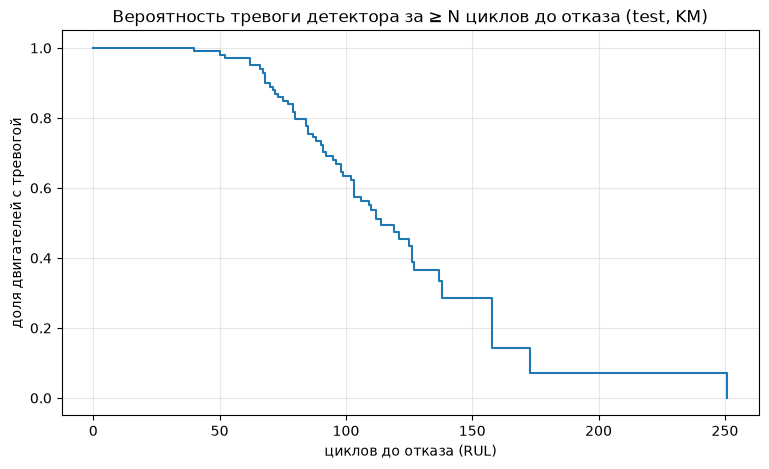

In [ ]:
times, events = [], []
for eng in sorted(test_clean['engine_id'].unique()):
    if det.get(eng, False):
        times.append(first_alarm[eng])   # событие: true_rul в момент тревоги
        events.append(1)
    else:
        times.append(rul[eng])           # цензура: RUL на момент обрыва записи
        events.append(0)

import numpy as np
t = np.sort(np.array(times, float))
e = np.array(events)[np.argsort(np.array(times, float))]
print('NaN в times:', np.isnan(t).sum())     # должно быть 0

km_t, km_p, prob = [0.0], [1.0], 1.0
for ti in np.unique(t[~np.isnan(t)]):
    n = (t >= ti).sum()
    d = e[t == ti].sum()
    if d > 0:
        prob *= (1 - d / n)
    km_t.append(ti); km_p.append(prob)

plt.figure(figsize=(9, 5))
plt.step(km_t, km_p, where='post')
plt.xlabel('циклов до отказа (RUL)')
plt.ylabel('доля двигателей с тревогой')
plt.title('Вероятность тревоги детектора за ≥ N циклов до отказа (test, KM)')
plt.grid(alpha=0.3)
plt.show()

Повторяющийся код выносим в функции: загрузка, чистка констант, детектор,
метрики детектора (с учётом цензурирования), графики. Дальше FD003/FD002/
FD004 работают через них — одна логика, сравнимые числа. FD001-секция
сохранена как история исследования (руками, с итерациями).

In [ ]:
def load_cmapss(dataset='FD001'):
    """Загружает train/test/RUL для поднабора CMAPSS."""
    cols = ['engine_id', 'cycle'] + [f'os_{i}' for i in range(1, 4)] + \
           [f'sensor_{i}' for i in range(1, 22)]
    train = pd.read_csv(f'train_{dataset}.txt', sep=r'\s+', header=None, names=cols)
    test  = pd.read_csv(f'test_{dataset}.txt',  sep=r'\s+', header=None, names=cols)
    rul   = pd.read_csv(f'RUL_{dataset}.txt',   sep=r'\s+', header=None, names=['RUL_true'])
    return train, test, rul

def clean_const(train, test, thresh=0.01):
    """Отбрасывает почти-константные колонки. Пересчитывается ДЛЯ КАЖДОГО набора."""
    std = train.std(numeric_only=True)
    const_cols = std[std < thresh].index.tolist()
    sensors = [c for c in train.columns
               if c.startswith('sensor') and c not in const_cols]
    return train.drop(columns=const_cols), test.drop(columns=const_cols), sensors

def apply_detector(df, sensors, first_n=30, k=5, sustain=5):
    """Детектор T: персональный эталон + дрейф. Параметры НЕ менять между наборами."""
    df = df.sort_values(['engine_id', 'cycle']).copy()
    trend_cols = []
    for s in sensors:
        col = f'{s}_trend'
        df[col] = False
        for eng, g in df.groupby('engine_id'):
            base = g.loc[g['cycle'] <= first_n, s]
            mu = base.mean()
            sd = base.std()
            if sd < 1e-6:
                sd = df[s].std()
            idx = g.index[g['cycle'] > first_n]
            ma = g.loc[idx, s].rolling(k, min_periods=1).mean()
            drift = (ma - mu).abs() > 2 * sd
            df.loc[idx, col] = (drift.rolling(sustain).sum() >= sustain).values
        trend_cols.append(col)
    return df, trend_cols

def detector_metrics(test_det, trend_cols, rul, healthy_rul=125):
    """Метрики детектора на тестовом наборе: true_rul, обнаружение,
    запас, ложные тревоги, strict/soft с учётом цензурирования."""
    eng_ids = sorted(test_det['engine_id'].unique())
    assert len(rul) == len(eng_ids), f'длина не совпала: {len(rul)} vs {len(eng_ids)}'

    r = pd.Series(rul['RUL_true'].values, index=eng_ids)
    fail_cycle = test_det.groupby('engine_id')['cycle'].max() + r
    test_det = test_det.copy()
    test_det['true_rul'] = test_det['engine_id'].map(fail_cycle) - test_det['cycle']

    alarm_row = test_det[trend_cols].any(axis=1)
    det = alarm_row.groupby(test_det['engine_id']).any()
    first_alarm = test_det.loc[alarm_row].groupby('engine_id')['true_rul'].max()

    hz = test_det[(test_det['true_rul'] >= healthy_rul) & (test_det['cycle'] > 30)]
    false_rate = hz[trend_cols].any(axis=1).mean()

    rul_s = pd.Series(rul['RUL_true'].values, index=eng_ids)
    q25, q75 = first_alarm.quantile([0.25, 0.75])
    strict_obs = rul_s <= q25
    soft_obs = rul_s <= q75

    print('Обнаружено:', round(float(det.mean()), 4))
    print(first_alarm.describe())
    print('Ложные тревоги:', round(float(false_rate), 4))
    print(f'строгий: обнаружено {det[strict_obs].mean():.0%} из {strict_obs.sum()}')
    print(f'мягкий: обнаружено {det[soft_obs].mean():.0%} из {soft_obs.sum()}')
    print('с тревогой:', int(det.sum()), '| валидный first_alarm:', int(first_alarm.notna().sum()))
    print('NaN в true_rul:', int(test_det['true_rul'].isna().sum()))

    return det, first_alarm, test_det

def plot_raw_sensors(df, sensors, n_engines=10, title=''):
    """Траектории сенсоров: один подграфик на сенсор, цвет = двигатель."""
    engines = sorted(df['engine_id'].unique())[:n_engines]
    sub = df[df['engine_id'].isin(engines)]

    n = len(sensors)
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
    for ax, s in zip(axes.flat, sensors):
        for eng in engines:
            g = sub[sub['engine_id'] == eng]
            ax.plot(g['cycle'], g[s], label=f'дв. {eng}', alpha=0.7)
        ax.set_title(s)
        ax.set_xlabel('цикл')
    for ax in axes.flat[n:]:
        ax.axis('off')
    if title:
        fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

def plot_aligned_degradation(df, sensors, title=''):
    """Усреднённая кривая деградации: все двигатели выровнены по
    'циклам до отказа', значения нормированы в [0,1] внутри двигателя."""
    d = df.copy()
    d['ctf'] = d.groupby('engine_id')['cycle'].transform('max') - d['cycle']
    for s in sensors:
        d[s] = d.groupby('engine_id')[s].transform(
            lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9))

    n = len(sensors)
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
    for ax, s in zip(axes.flat, sensors):
        g = d.groupby('ctf')[s].agg(['mean', 'std'])
        ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], alpha=0.2)
        ax.plot(g.index, g['mean'])
        ax.invert_xaxis()
        ax.set_title(s)
        ax.set_xlabel('циклов до отказа')
    for ax in axes.flat[n:]:
        ax.axis('off')
    if title:
        fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

## Глава 5. Перенос на другой тип отказа (FD003)

Оба компонента, настроенные на FD001 (отказы КВД), применяем к FD003
(отказы вентилятора) без переобучения. Вопрос эксперимента: универсальны
ли компоненты, и если нет — что именно ломается.

In [ ]:
train3, test3, rul3 = load_cmapss('FD003')
train3_clean, test3_clean, sensors3 = clean_const(train3, test3, thresh=CONFIG['std_thresh'])

# МОДЕЛЬ: признаки — те, на которых она училась (sensors из FD001!)
model_rul = joblib.load('model_rul_fd001.pkl')

pred3 = model_rul.predict(test3_clean.groupby('engine_id')[sensors].last())
print('RMSE FD003:', np.sqrt(mean_squared_error(rul3['RUL_true'], pred3)))

# ДЕТЕКТОР: чистка и эталон — собственные, FD003
test3_det, trend_cols3 = apply_detector(test3_clean, sensors3,
                                          first_n=CONFIG['first_n'],
                                          k=CONFIG['k'],
                                          sustain=CONFIG['sustain'])

RMSE FD003: 26.42875593207463


**Результаты FD003.** Модель: RMSE вырос с 17.92 до 26.43 (+47%; наивный
прогноз 41.40) — универсальный сигнал старения модель удерживает,
специфичную часть теряет. Детектор: сохранил чувствительность (strict 89%,
медианный запас 126 циклов), но ценой роста ложных тревог (18.6% против
1.6% на FD001) — калибровка «дрейф → время до отказа» специфична типу
отказа.

Константные FD003: ['os_1', 'os_2', 'os_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


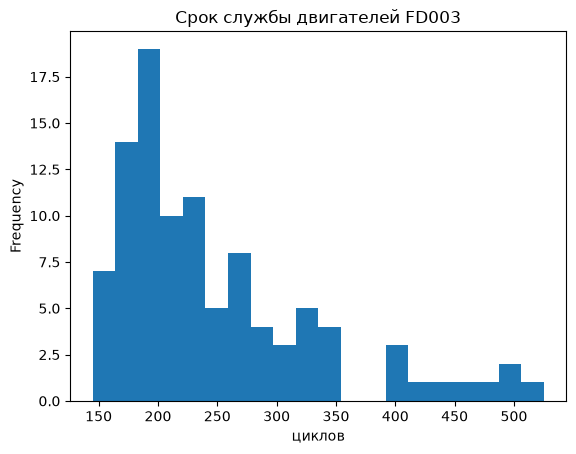

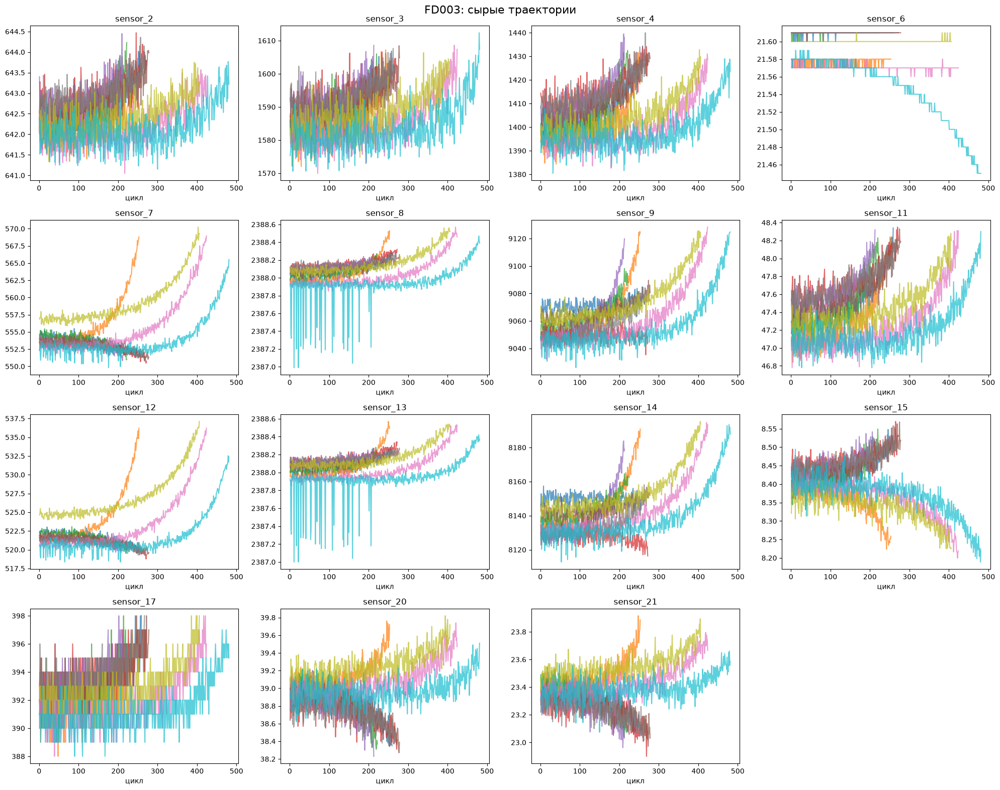

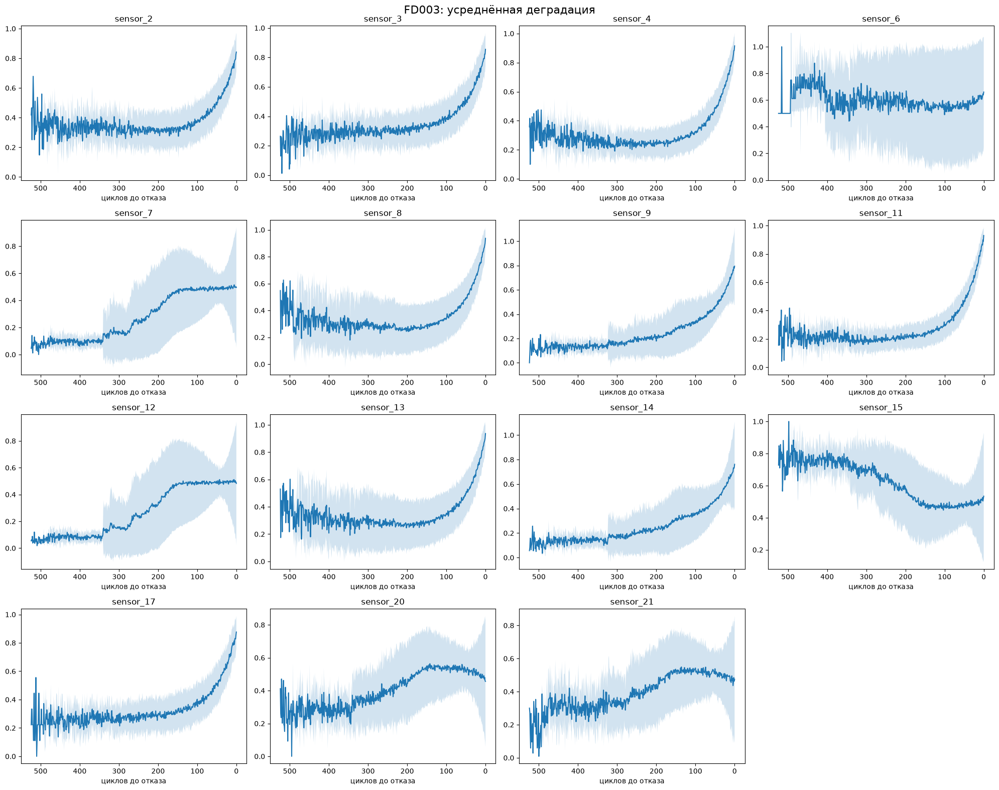

In [ ]:
# константные каналы FD003 — сравните с FD001, список другой
zero3 = train3.std(numeric_only=True)
print('Константные FD003:', zero3[zero3 < 0.01].index.tolist())

# распределение ресурса
train3.groupby('engine_id')['cycle'].max().plot.hist(
    bins=20, title='Срок службы двигателей FD003')
plt.xlabel('циклов'); plt.show()

plot_raw_sensors(train3, sensors3, n_engines=10, title='FD003: сырые траектории')
plot_aligned_degradation(train3, sensors3, title='FD003: усреднённая деградация')

Особенности FD003: sensor_6 (P15, байпас) вариативен, но тренда деградации
не несёт — это квантование датчика (17 уровней), ограничение фильтра по std.
Провалы вентиляторной частоты (Nf/NRf) до общего нижнего уровня (~2386.9)
дают несколько агрегатов — системный режимный/измерительный эффект, а не
индивидуальная неисправность. Рейтинг сенсоров по тревожности частично
подтвердил физику: вентиляторные каналы (8, 13, 15) поднялись в топ, но
доминируют каналы ядра — деградация вентилятора распространяется на
компрессорный тракт.

In [ ]:
# кто даёт глубокие провалы вентиляторной частоты
mins8 = train3.groupby('engine_id')['sensor_8'].min()
print(mins8.sort_values().head(5))

# лесенка в sensor_6 — квантование датчика?
print(train3['sensor_6'].nunique(), 'уникальных значений у sensor_6')
print(train3['sensor_6'].diff().abs().value_counts().head(5))  # типичные шаги

engine_id
55    2386.90
42    2386.93
62    2386.98
10    2386.99
89    2386.99
Name: sensor_8, dtype: float64
17 уникальных значений у sensor_6
sensor_6
0.00    20827
0.01     2244
0.01     1599
0.02       16
0.03       15
Name: count, dtype: int64


Провалы вентиляторной частоты (Nf/NRf) до общего нижнего уровня (~2386.9)
дают несколько агрегатов — похоже на системный режимный/измерительный
эффект, а не на индивидуальную неисправность.

Наивный прогноз на третьем наборе данных

In [ ]:
naive = np.full(len(rul3), rul3['RUL_true'].mean())
print('Наивный бейзлайн FD003:',
      np.sqrt(mean_squared_error(rul3['RUL_true'], naive)))

Наивный бейзлайн FD003: 41.39562295702289


In [ ]:
det3, first_alarm3, test3_det = detector_metrics(test3_det, trend_cols3, rul3)

Обнаружено: 0.72
count     72.000000
mean     136.208333
std       54.671345
min       52.000000
25%       92.000000
50%      126.000000
75%      158.500000
max      276.000000
Name: true_rul, dtype: float64
Ложные тревоги: 0.1857
строгий: обнаружено 89% из 64
мягкий: обнаружено 72% из 100
с тревогой: 72 | валидный first_alarm: 72
NaN в true_rul: 0


In [ ]:
# # 0. истинный момент отказа каждого тестового двигателя FD003
# eng_ids3 = sorted(test3_clean['engine_id'].unique())
# r3 = pd.Series(rul_test['RUL_true'].values, index=eng_ids1)
# last3_cycle = test3_clean.groupby('engine_id')['cycle'].max()
# fail_cycle3 = last3_cycle + r3
# test3_det['true_rul'] = (test3_det['engine_id'].map(fail_cycle3)
#                          - test3_det['cycle'])

# # 1. метрики
# alarm_row = test3_det[trend_cols3].any(axis=1)
# det = alarm_row.groupby(test3_det['engine_id']).any()
# print('Обнаружено:', det.mean())

# first_alarm = test3_det.loc[alarm_row].groupby('engine_id')['true_rul'].max()
# print(first_alarm.describe())

# hz = test3_det[(test3_det['true_rul'] >= 125) & (test3_det['cycle'] > 30)]
# print('Ложные тревоги:', hz[trend_cols3].any(axis=1).mean())

In [ ]:
alarm_rate = test3_det[trend_cols3].mean().sort_values(ascending=False)
print(alarm_rate.head(10))

sensor_12_trend    0.230116
sensor_7_trend     0.213485
sensor_9_trend     0.169800
sensor_14_trend    0.167570
sensor_8_trend     0.121596
sensor_13_trend    0.120872
sensor_11_trend    0.099663
sensor_15_trend    0.077790
sensor_4_trend     0.057182
sensor_20_trend    0.047783
dtype: float64


In [ ]:
rul3s = rul3['RUL_true'].copy()
rul3s.index = det.index                     # det — из вашей исправленной FD003-ячейки
for thr, name in [(92, 'строгий'), (158, 'мягкий')]:
    observable = rul3s <= thr
    print(f'FD003 {name}: обнаружено {det[observable].mean():.0%} '
          f'из {observable.sum()}')

FD003 строгий: обнаружено 56% из 64
FD003 мягкий: обнаружено 58% из 100


## Глава 6. Рабочие режимы (FD002)

FD002 — те же отказы КВД, но 6 лётных условий (высота × число Маха),
меняющихся каждые 1–2 цикла. Перенос FD001→FD002 без переобучения:
модель почти умерла (49.83 против наивных 53.78 — модель не бьёт константу),
детектор оглох (обнаружение 3.5%). Гипотеза: режимная несравнимость.
Проверяем, разбирая режимы.

In [ ]:
train2, test2, rul2 = load_cmapss('FD002')
train2_clean, test2_clean, sensors2 = clean_const(train2, test2)

# МОДЕЛЬ без переобучения
model_rul = joblib.load('model_rul_fd001.pkl')

pred2 = model_rul.predict(test2_clean.groupby('engine_id')[sensors].last())
print('RMSE FD002:', np.sqrt(mean_squared_error(rul2['RUL_true'], pred2)))
naive2 = np.full(len(rul2), rul2['RUL_true'].mean())
print('Наивный FD002:', np.sqrt(mean_squared_error(rul2['RUL_true'], naive2)))

# ДЕТЕКТОР без изменений
test2_det, trend_cols2 = apply_detector(test2_clean, sensors2)


RMSE FD002: 49.83469153018607
Наивный FD002: 53.77879418187779


In [ ]:
det2, first_alarm2, test2_det = detector_metrics(test2_det, trend_cols2, rul2)

Обнаружено: 0.0347
count      9.000000
mean     125.444444
std       57.686894
min       26.000000
25%       74.000000
50%      150.000000
75%      160.000000
max      198.000000
Name: true_rul, dtype: float64
Ложные тревоги: 0.0009
строгий: обнаружено 5% из 118
мягкий: обнаружено 3% из 233
с тревогой: 9 | валидный first_alarm: 9
NaN в true_rul: 0


In [ ]:
# # 0. истинный момент отказа каждого тестового двигателя FD002
# last_cycle2 = test2_det.groupby('engine_id')['cycle'].max()
# r2 = rul2['RUL_true'].copy()
# r2.index = last_cycle2.index                # совмещаем по позициям
# fail_cycle2 = last_cycle2 + r2
# test2_det['true_rul'] = (test2_det['engine_id'].map(fail_cycle3)
#                          - test2_det['cycle'])

# # 1. метрики
# alarm_row = test2_det[trend_cols2].any(axis=1)
# det = alarm_row.groupby(test2_det['engine_id']).any()
# print('Обнаружено:', det.mean())

# first_alarm = test2_det.loc[alarm_row].groupby('engine_id')['true_rul'].max()
# print(first_alarm.describe())

# hz = test2_det[(test2_det['true_rul'] >= 125) & (test2_det['cycle'] > 30)]
# print('Ложные тревоги:', hz[trend_cols2].any(axis=1).mean())

In [ ]:
# rul2s = rul2['RUL_true'].copy()
# rul2s.index = det.index                     # det — из вашей исправленной FD003-ячейки
# for thr, name in [(92, 'строгий'), (158, 'мягкий')]:
#     observable = rul2s <= thr
#     print(f'FD002 {name}: обнаружено {det[observable].mean():.0%} '
#           f'из {observable.sum()}')

In [ ]:
# # FD002: метрики + strict/soft + диагностика
# # (детектор уже посчитан — apply_detector НЕ запускаем)

# # 1. true_rul — позиционное совмещение
# eng_ids = sorted(test2_det['engine_id'].unique())
# print('двигателей:', len(eng_ids), '| строк в rul2:', len(rul2))
# r2 = pd.Series(rul2['RUL_true'].values, index=eng_ids)
# last_cycle2 = test2_det.groupby('engine_id')['cycle'].max()
# fail_cycle2 = last_cycle2 + r2
# test2_det['true_rul'] = (test2_det['engine_id'].map(fail_cycle2)
#                          - test2_det['cycle'])

# # 2. метрики
# alarm_row2 = test2_det[trend_cols2].any(axis=1)
# det2 = alarm_row2.groupby(test2_det['engine_id']).any()
# print('Обнаружено:', round(float(det2.mean()), 4))

# first_alarm2 = test2_det.loc[alarm_row2].groupby('engine_id')['true_rul'].max()
# print(first_alarm2.describe())

# hz2 = test2_det[(test2_det['true_rul'] >= 125) & (test2_det['cycle'] > 30)]
# print('Ложные тревоги:', round(float(hz2[trend_cols2].any(axis=1).mean()), 4))

# # 3. strict/soft
# rul2s = pd.Series(rul2['RUL_true'].values, index=eng_ids)
# q25, q75 = first_alarm2.quantile([0.25, 0.75])
# for thr, name in [(int(q25), 'строгий'), (int(q75), 'мягкий')]:
#     observable = rul2s <= thr
#     print(f'FD002 {name}: обнаружено {det2[observable].mean():.0%} из {observable.sum()}')

# # 4. диагностика
# print('с тревогой:', int(det2.sum()),
#       '| с валидным first_alarm:', int(first_alarm2.notna().sum()))
# print('NaN в true_rul:', int(test2_det['true_rul'].isna().sum()))

### EDA FD002

Константные FD002: ['sensor_16']


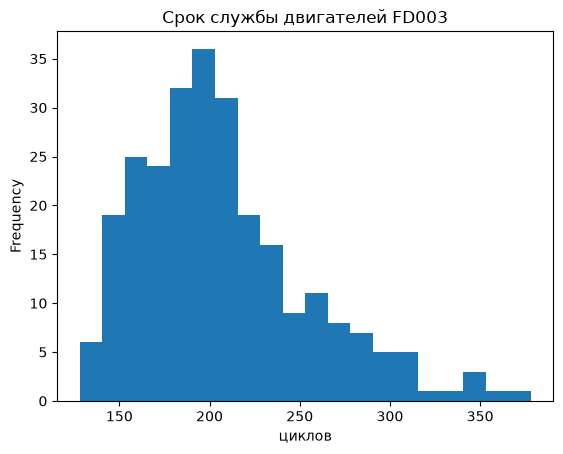

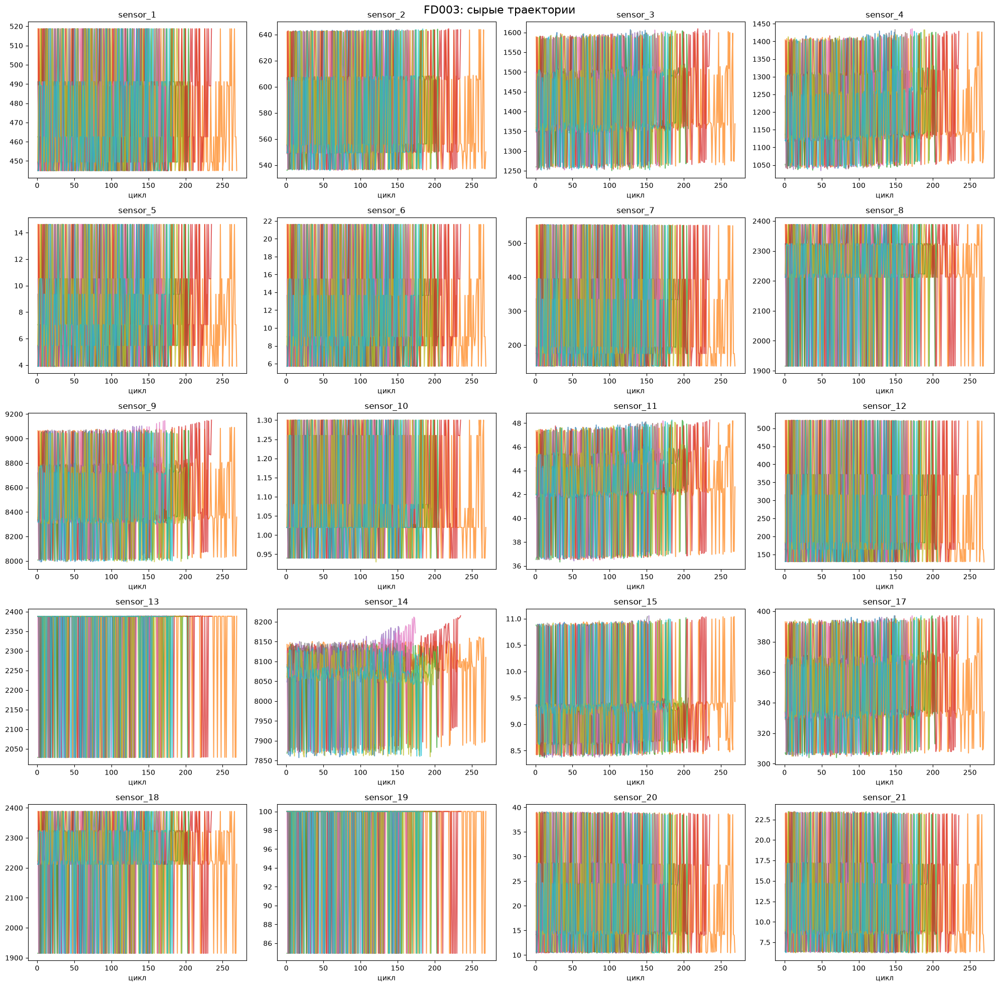

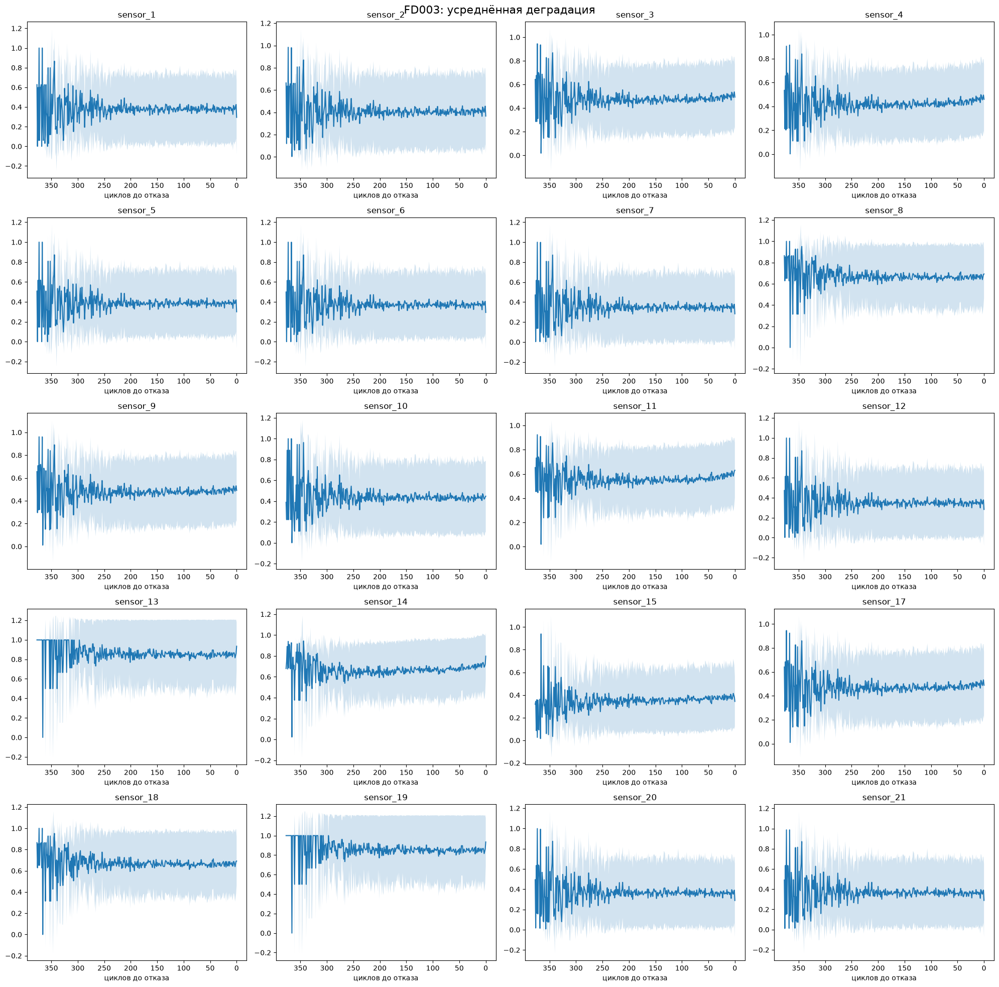

In [ ]:
zero2 = train2.std(numeric_only=True)
print('Константные FD002:', zero2[zero2 < 0.01].index.tolist())

# распределение ресурса
train2.groupby('engine_id')['cycle'].max().plot.hist(
    bins=20, title='Срок службы двигателей FD003')
plt.xlabel('циклов'); plt.show()

plot_raw_sensors(train2, sensors2, n_engines=10, title='FD003: сырые траектории')
plot_aligned_degradation(train2, sensors2, title='FD003: усреднённая деградация')

### Определение комбинаций режимов 

Используем метод k-means

уникальных комбинаций os: 9824
regime
0    13458
1     8122
2     8002
3     8044
4     8096
5     8037
Name: count, dtype: int64


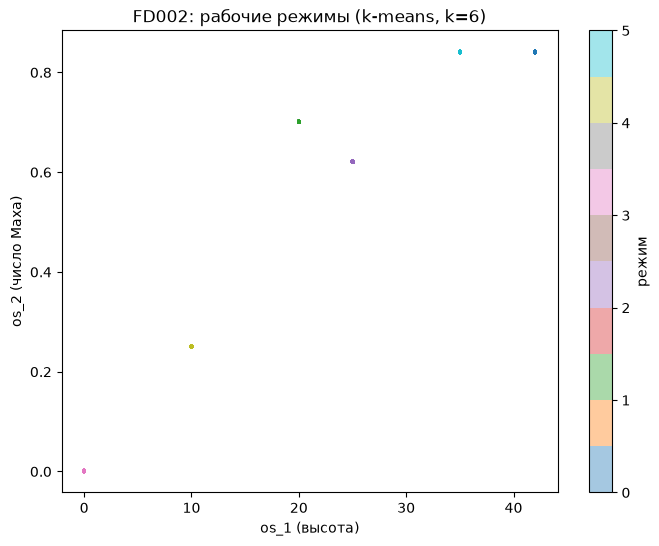

In [ ]:
from sklearn.cluster import KMeans

# уникальные комбинации режимов — сколько их вообще?
uniq = train2[['os_1', 'os_2', 'os_3']].drop_duplicates()
print('уникальных комбинаций os:', len(uniq))

# метка режима каждой строке
km = KMeans(n_clusters=6, random_state=42, n_init=10)
train2['regime'] = km.fit_predict(train2[['os_1', 'os_2', 'os_3']])
print(train2['regime'].value_counts().sort_index())

# скаттер: режимы видны?
plt.figure(figsize=(8, 6))
plt.scatter(train2['os_1'], train2['os_2'], c=train2['regime'], s=2, alpha=0.4, cmap='tab10')
plt.xlabel('os_1 (высота)'); plt.ylabel('os_2 (число Маха)')
plt.title('FD002: рабочие режимы (k-means, k=6)')
plt.colorbar(label='режим')
plt.show()

Разобьем данные по режимам работы и еще раз посмотрим графики

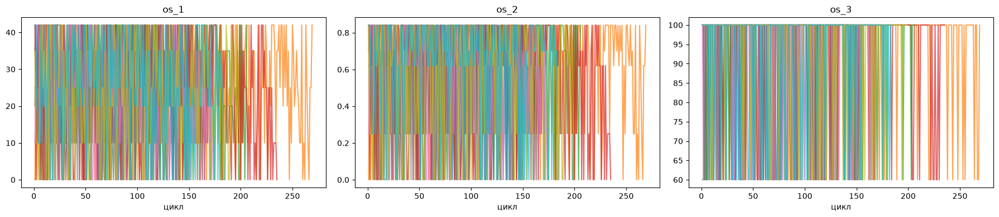

os_1 - уникальных: 536
os_2 - уникальных: 105
os_3 - уникальных: 2


In [ ]:
# как os_1, os_2, os_3 меняются по циклам у первых 10 двигателей
engines = sorted(train2['engine_id'].unique())[:10]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, os_col in zip(axes, ['os_1', 'os_2', 'os_3']):
    for eng in engines:
        g = train2[train2['engine_id'] == eng]
        ax.plot(g['cycle'], g[os_col], alpha=0.7)
    ax.set_title(os_col)
    ax.set_xlabel('цикл')
plt.tight_layout()
plt.show()

# сколько у каждого уникальных значений
for os_col in ['os_1', 'os_2', 'os_3']:
    print(os_col, '- уникальных:', train2[os_col].nunique())

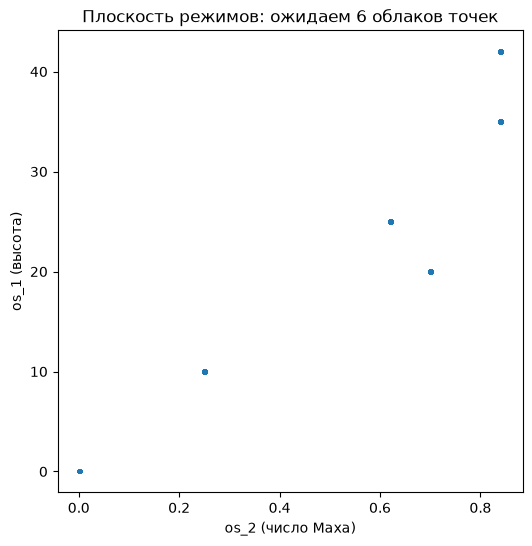

уникальных пар (os_1, os_2): 9824


In [ ]:
# 6 лётных условий — это 6 точек на плоскости высота/скорость
plt.figure(figsize=(6, 6))
plt.scatter(train2['os_2'], train2['os_1'], s=3, alpha=0.3)
plt.xlabel('os_2 (число Маха)')
plt.ylabel('os_1 (высота)')
plt.title('Плоскость режимов: ожидаем 6 облаков точек')
plt.show()

pairs = train2[['os_1', 'os_2']].drop_duplicates()
print('уникальных пар (os_1, os_2):', len(pairs))

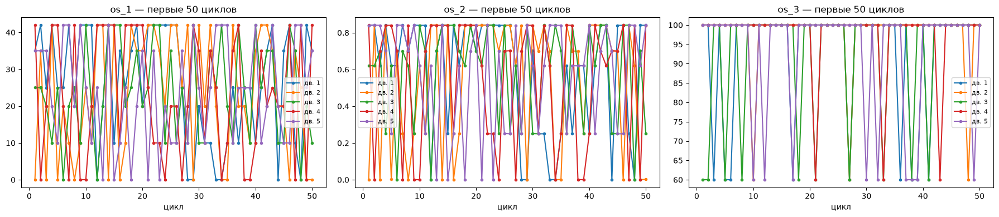

In [ ]:
# молодость двигателя — та самая зона эталона
engines = sorted(train2['engine_id'].unique())[:5]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, os_col in zip(axes, ['os_1', 'os_2', 'os_3']):
    for eng in engines:
        g = train2[(train2['engine_id'] == eng) & (train2['cycle'] <= 50)]
        ax.plot(g['cycle'], g[os_col], 'o-', markersize=3, label=f'дв. {eng}')
    ax.set_title(os_col + ' — первые 50 циклов')
    ax.set_xlabel('цикл')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

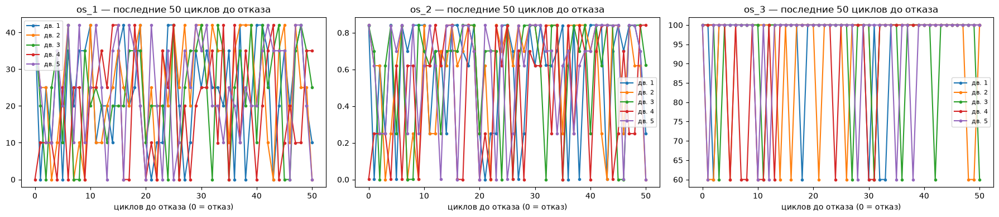

In [ ]:
# «циклов до отказа» — общий счётчик для всех, независимо от длины жизни
train2['ctf'] = train2.groupby('engine_id')['cycle'].transform('max') - train2['cycle']

engines = sorted(train2['engine_id'].unique())[:5]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, os_col in zip(axes, ['os_1', 'os_2', 'os_3']):
    for eng in engines:
        g = train2[(train2['engine_id'] == eng) & (train2['ctf'] <= 50)]
        ax.plot(g['ctf'], g[os_col], 'o-', markersize=3, label=f'дв. {eng}')
    ax.set_title(os_col + ' — последние 50 циклов до отказа')
    ax.set_xlabel('циклов до отказа (0 = отказ)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:

# точная метка режима — пара (os_1, os_2)
pairs = train2[['os_1', 'os_2']].drop_duplicates().sort_values(['os_1', 'os_2'])
pair_ids = {tuple(p): i for i, p in enumerate(pairs.values)}
train2['regime'] = [pair_ids[(a, b)] for a, b in zip(train2['os_1'], train2['os_2'])]

# сколько циклов каждого режима в первые 30 (наше эталонное окно)
base = train2[train2['cycle'] <= 30].groupby('engine_id')['regime'].value_counts().unstack().fillna(0)
print(base.describe().loc[['min', '50%', 'max']].round(1).to_string())

regime  0     1     2     4     6     8     10    11    12    14    15    16    21    22    23    25    26    28    30    31    32    33    35    36    37    38    40    42    43    45    47    48    49    51    52    54    55    56    57    58    59    61    62    63    65    66    69    71    76    77    78    79    82    83    84    85    86    87    88    90    92    95    96    98    100   101   102   105   106   108   110   111   112   115   116   120   122   123   124   125   126   127   128   129   132   134   136   141   142   143   144   145   146   147   148   149   150   151   152   155   157   159   161   162   163   164   165   166   168   170   171   173   174   175   176   177   181   182   183   185   187   189   190   191   195   197   198   199   200   201   204   205   210   213   214   215   216   217   218   219   220   221   223   224   225   226   227   228   229   231   233   238   241   245   246   247   250   251   252   254   255   257   260   264   267   26

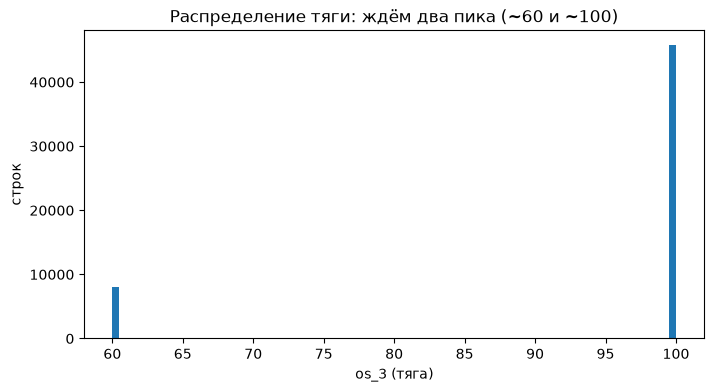

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(train2['os_3'], bins=80)
plt.xlabel('os_3 (тяга)')
plt.ylabel('строк')
plt.title('Распределение тяги: ждём два пика (~60 и ~100)')
plt.show()

In [ ]:
from sklearn.cluster import KMeans

km_thr = KMeans(n_clusters=2, random_state=42, n_init=10)
train2['thr_level'] = km_thr.fit_predict(train2[['os_3']])

centers = sorted(km_thr.cluster_centers_.flatten())
print('центры уровней тяги:', [round(c, 1) for c in centers])
print(train2['thr_level'].value_counts().sort_index())

центры уровней тяги: [np.float64(60.0), np.float64(100.0)]
thr_level
0    45757
1     8002
Name: count, dtype: int64


In [ ]:
# режим строки = (высота, скорость) + уровень тяги
pairs = train2[['os_1', 'os_2']].drop_duplicates().sort_values(['os_1', 'os_2'])
pair_ids = {tuple(p): i for i, p in enumerate(pairs.values)}
train2['regime'] = [pair_ids[(a, b)] for a, b in zip(train2['os_1'], train2['os_2'])]
train2['regime_full'] = train2['regime'] * 10 + train2['thr_level']   # 12 условий

# стационарность: режим совпадает с режимом 1 и 2 циклами раньше (внутри двигателя!)
g = train2.groupby('engine_id')['regime_full']
steady3 = (train2['regime_full'] == g.shift(1)) & (train2['regime_full'] == g.shift(2))
train2['steady'] = steady3.fillna(False)

print('всего строк:', len(train2))
print('стационарных (>=3 циклов в условии):', train2['steady'].sum(),
      f'({train2["steady"].mean():.0%})')

всего строк: 53759
стационарных (>=3 циклов в условии): 0 (0%)


In [ ]:
# длина сегмента: сколько подряд строк держится regime_full
run_len = train2.groupby('engine_id')['regime_full'].transform(
    lambda x: x.groupby((x != x.shift()).cumsum()).cumcount() + 1)

print(run_len.describe().round(2).to_string())
print()
print('доля сегментов длины 1:', f'{(run_len == 1).mean():.0%}')
print('доля сегментов длины 2:', f'{(run_len == 2).mean():.0%}')
print('доля сегментов длины >=3:', f'{(run_len >= 3).mean():.0%}')

count    53759.00
mean         1.00
std          0.02
min          1.00
25%          1.00
50%          1.00
75%          1.00
max          2.00

доля сегментов длины 1: 100%
доля сегментов длины 2: 0%
доля сегментов длины >=3: 0%


Находка FD002: режимы меняются почти каждый цикл — длительных
стационарных окон нет (0% строк держат условие 3 цикла подряд).
Фильтр переходных режимов строится по изолированным визитам,
а не по длинным окнам. Изначальный план «3 цикла подряд» отменён
данными, не предположением.

In [ ]:
# 15 подряд идущих строк двигателя 1: как на самом деле меняются os
cols = ['engine_id', 'cycle', 'os_1', 'os_2', 'os_3', 'regime_full']
print(train2.loc[train2['engine_id'] == 1, cols].head(15).to_string(index=False))

 engine_id  cycle    os_1   os_2  os_3  regime_full
         1      1 34.9983 0.8400 100.0        60860
         1      2 41.9982 0.8408 100.0        78660
         1      3 24.9988 0.6218  60.0        44001
         1      4 42.0077 0.8416 100.0        97610
         1      5 25.0005 0.6203  60.0        46831
         1      6 25.0045 0.6205  60.0        53921
         1      7 42.0043 0.8409 100.0        90860
         1      8 20.0020 0.7002 100.0        31500
         1      9 41.9995 0.8407 100.0        81270
         1     10 42.0011 0.8400 100.0        84390
         1     11 42.0029 0.8400 100.0        87990
         1     12  0.0015 0.0010 100.0         3250
         1     13 20.0003 0.7000 100.0        28580
         1     14 42.0020 0.8407 100.0        86240
         1     15 10.0038 0.2513 100.0        17020


In [ ]:
# режимы — по номиналам: округляем дрожание
train2['alt'] = train2['os_1'].round(1)    # 0 / 10 / 20 / 25 / 35 / 42
train2['mach'] = train2['os_2'].round(2)   # 0.00 / 0.25 / 0.62 / 0.70 / 0.84

pairs = train2[['alt', 'mach']].drop_duplicates().sort_values(['alt', 'mach'])
print('уникальных пар после округления:', len(pairs))
print(pairs.to_string(index=False))

pair_ids = {tuple(p): i for i, p in enumerate(pairs.values)}
train2['regime'] = [pair_ids[(a, b)] for a, b in zip(train2['alt'], train2['mach'])]
train2['regime_full'] = train2['regime'] * 10 + train2['thr_level']   # 12 ячеек

# повторяем анализ сегментов — теперь честно
run_len = train2.groupby('engine_id')['regime_full'].transform(
    lambda x: x.groupby((x != x.shift()).cumsum()).cumcount() + 1)
print()
print(run_len.describe().round(2).to_string())
print('доля сегментов длины 1:', f'{(run_len == 1).mean():.0%}')
print('доля сегментов длины 2:', f'{(run_len == 2).mean():.0%}')
print('доля сегментов >=3:', f'{(run_len >= 3).mean():.0%}')

# и проверка стационарности заново
g = train2.groupby('engine_id')['regime_full']
steady3 = ((train2['regime_full'] == g.shift(1)) &
           (train2['regime_full'] == g.shift(2))).fillna(False)
print('стационарных >=3 циклов:', f'{steady3.mean():.0%}')

уникальных пар после округления: 6
 alt  mach
 0.0  0.00
10.0  0.25
20.0  0.70
25.0  0.62
35.0  0.84
42.0  0.84

count    53759.00
mean         1.22
std          0.52
min          1.00
25%          1.00
50%          1.00
75%          1.00
max          7.00
доля сегментов длины 1: 83%
доля сегментов длины 2: 14%
доля сегментов >=3: 3%
стационарных >=3 циклов: 3%


Данные FD002 почти полностью динамичны: 83% строк — одиночные визиты
в условие по 1–2 цикла, стационарных окон (≥3 циклов) — 3%. Фильтр
стационарности невозможен и не нужен: непрерывных переходов нет, os_3
скачет 60→100 за один цикл, каждая строка — валидное измерение на наборном
пункте. Гипотеза «выкинуть шумные переходы» не подтвердилась — записываем
как отрицательный результат.

Лечение режимной несравнимости — не фильтрация, а нормировка: z = (значение
− среднее условия) / σ условия, статистики по здоровым строкам (RUL ≥ 125)
внутри каждого из 12 условий. Защита от σ≈0 (квантованный sensor_6):
z обнуляется — «нет информации» честнее «бесконечное отклонение».

In [ ]:
# 1. таргет для train2 (та же конвенция, что FD001)
max_cycle2 = train2.groupby('engine_id')['cycle'].transform('max')
train2['RUL'] = (max_cycle2 - train2['cycle']).clip(upper=CONFIG['clip'])

# 2. статистика условий — только по здоровым строкам
healthy2 = train2[train2['RUL'] >= CONFIG['clip']]

# режимы test2 — ТЕМИ ЖЕ ключами, что train2
test2['alt'] = test2['os_1'].round(1)
test2['mach'] = test2['os_2'].round(2)
test2['thr_level'] = km_thr.predict(test2[['os_3']])
test2['regime'] = [pair_ids[(a, b)] for a, b in zip(test2['alt'], test2['mach'])]
test2['regime_full'] = test2['regime'] * 10 + test2['thr_level']

# 3. z-нормировка по ячейкам
zcols = []
for s in sensors2:
    mu = healthy2.groupby('regime_full')[s].mean()
    sd = healthy2.groupby('regime_full')[s].std()
    for df in (train2, test2):
        df[f'{s}_z'] = (df[s] - df['regime_full'].map(mu)) / df['regime_full'].map(sd)
    zcols.append(f'{s}_z')

# 4. защита от вырождения: где σ ячейки ≈ 0 (sensor_6!) — z обнуляем
for s in sensors2:
    for df in (train2, test2):
        bad = df['regime_full'].map(healthy2.groupby('regime_full')[s].std()) < 1e-6
        df.loc[bad, f'{s}_z'] = 0.0

# 5. проверка
print('NaN в z-признаках:', train2[zcols].isna().sum().sum())
print(train2[zcols].describe().loc[['mean', 'std']].round(2).to_string())

NaN в z-признаках: 0
      sensor_1_z  sensor_2_z  sensor_3_z  sensor_4_z  sensor_5_z  sensor_6_z  sensor_7_z  sensor_8_z  sensor_9_z  sensor_10_z  sensor_11_z  sensor_12_z  sensor_13_z  sensor_14_z  sensor_15_z  sensor_17_z  sensor_18_z  sensor_19_z  sensor_20_z  sensor_21_z
mean         0.0         0.7        0.67        0.91         0.0        0.36       -0.54        0.75        0.73         0.03         1.01        -0.58         0.76         0.51         0.89         0.72          0.0          0.0        -0.49        -0.48
std          0.0         1.3        1.28        1.47         0.0        1.10        1.24        2.09        2.20         1.95         1.56         1.28         2.12         2.07         1.47         1.32          0.0          0.0         1.20         1.19


In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score

gkf = GroupKFold(n_splits=5)
groups = train2['engine_id']
y2 = train2['RUL']

model = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                          num_leaves=31, random_state=CONFIG['random_state'],
                          verbose=-1)

# A: сырые сенсоры
s_raw = -cross_val_score(model, train2[sensors2], y2, groups=groups,
                         scoring='neg_root_mean_squared_error', cv=gkf, n_jobs=-1)

# B: сырые + метка режима (модель сама учит поправки на условия)
s_raw_reg = -cross_val_score(model, train2[sensors2 + ['regime_full']], y2,
                             groups=groups,
                             scoring='neg_root_mean_squared_error', cv=gkf, n_jobs=-1)

# C: z-нормированные (режимная информация уже внутри нормировки)
s_z = -cross_val_score(model, train2[zcols], y2, groups=groups,
                       scoring='neg_root_mean_squared_error', cv=gkf, n_jobs=-1)

print(f'A сырые:              {s_raw.mean():.2f} ± {s_raw.std():.2f}')
print(f'B сырые + режим:      {s_raw_reg.mean():.2f} ± {s_raw_reg.std():.2f}')
print(f'C z-нормированные:    {s_z.mean():.2f} ± {s_z.std():.2f}')

A сырые:              19.85 ± 0.67
B сырые + режим:      19.85 ± 0.67
C z-нормированные:    19.62 ± 0.68


**Три варианта модели на FD002** (GroupKFold, единый протокол): сырые сенсоры
19.85 ± 0.67; сырые + метка режима 19.85 (метка не использована деревьями —
режим детерминирован из показаний); z-нормированные 19.62 ± 0.68 (прирост
в пределах шума). Вывод: обучаемой модели нормировка не нужна — бустинг сам
находит режимную структуру. Это тот же принцип, что и с rolling-признаками
на FD001: сырые сенсоры + градиентный бустинг неулучшимы предобработкой.

In [ ]:
# детектор v2: режимная норма внутри z, правило прежнее
test2_det_z, trend_cols2z = apply_detector(test2, zcols,
                                           first_n=CONFIG['first_n'],
                                           k=CONFIG['k'],
                                           sustain=CONFIG['sustain'])

det2z, first_alarm2z, test2_det_z = detector_metrics(test2_det_z, trend_cols2z, rul2)

Обнаружено: 0.6988
count    181.000000
mean     130.917127
std       52.441383
min       27.000000
25%       90.000000
50%      128.000000
75%      163.000000
max      310.000000
Name: true_rul, dtype: float64
Ложные тревоги: 0.0407
строгий: обнаружено 91% из 149
мягкий: обнаружено 74% из 235
с тревогой: 181 | валидный first_alarm: 181
NaN в true_rul: 0


**Детектор v2: детектор T на z-значениях.** Правило не менялось — эталон
30 циклов, дрейф 5 подряд. Обнаружение вернулось с 3.5% до strict 91%
(ложные тревоги 4.1%, медианный запас 128 циклов). Вывод, ставший одним
из принципов проекта: предобработка не улучшает обучаемую модель, но
критична для не-обучаемого детектора — правило ничему не учится, и для
него режимная несравнимость была смертельной.

In [ ]:
# финальные модели FD002 (A/B/C показали: raw и z одинаковы — сохраняем обе)
final_raw = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                              num_leaves=31, random_state=CONFIG['random_state'],
                              verbose=-1)
final_raw.fit(train2[sensors2], train2['RUL'])

final_z = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                            num_leaves=31, random_state=CONFIG['random_state'],
                            verbose=-1)
final_z.fit(train2[zcols], train2['RUL'])

# пайплайн целиком: модели + статистика нормировки + ключи режимов
stats_mu = {s: healthy2.groupby('regime_full')[s].mean() for s in sensors2}
stats_sd = {s: healthy2.groupby('regime_full')[s].std() for s in sensors2}

joblib.dump({'model_raw': final_raw, 'model_z': final_z,
             'pair_ids': pair_ids, 'km_thr': km_thr,
             'stats_mu': stats_mu, 'stats_sd': stats_sd,
             'sensors': sensors2, 'zcols': zcols},
            'pipeline_fd002.pkl')
print('сохранено: pipeline_fd002.pkl')

сохранено: pipeline_fd002.pkl


## Глава 7. Смешанные отказы и маршрутизатор типов (FD004)

FD004 — 6 режимов и два типа отказа (КВД + вентилятор) в одной партии.
Экзамен пайплайна: применяем обученный на FD002 пайплайн (модели +
статистики нормировки + ключи режимов, сохранены в pipeline_fd002.pkl)
без переобучения. Все прогнозы зафиксированы до запуска.

In [ ]:
train4, test4, rul4 = load_cmapss('FD004')
pipe = joblib.load('pipeline_fd002.pkl')

# 0. проверка условий: те же 6 пар и 2 тяги?
print('пары FD004:', sorted(set(zip(test4['os_1'].round(1), test4['os_2'].round(2)))))
print('os_3 FD004:', sorted(test4['os_3'].unique()))

# 1. режимы — ключами FD002
test4['alt'] = test4['os_1'].round(1)
test4['mach'] = test4['os_2'].round(2)
test4['thr_level'] = pipe['km_thr'].predict(test4[['os_3']])
missing = set(zip(test4['alt'], test4['mach'])) - set(pipe['pair_ids'])
assert not missing, f'в FD004 есть незнакомые условия: {missing}'
test4['regime'] = [pipe['pair_ids'][(a, b)] for a, b in zip(test4['alt'], test4['mach'])]
test4['regime_full'] = test4['regime'] * 10 + test4['thr_level']

# 2. z-нормировка — статистиками FD002
sensors_p = pipe['sensors']
for s in sensors_p:
    mu = test4['regime_full'].map(pipe['stats_mu'][s])
    sd = test4['regime_full'].map(pipe['stats_sd'][s])
    z = (test4[s] - mu) / sd
    test4[f'{s}_z'] = z.where(sd >= 1e-6, 0.0)   # защита от σ≈0
zcols4 = [f'{s}_z' for s in sensors_p]

# 3. модель: прогноз по ПОСЛЕДНЕМУ циклу каждого двигателя (протокол как всегда)
last4 = test4.groupby('engine_id')

p_raw = pipe['model_raw'].predict(last4[sensors_p].last())
p_z = pipe['model_z'].predict(last4[zcols4].last())
p_naive = np.full(len(rul4), rul4['RUL_true'].mean())

# страховка: согласованность файлов
print('двигателей в test4:', test4['engine_id'].nunique(),
      '| строк в rul4:', len(rul4))

for name, p in [('raw', p_raw), ('z', p_z), ('naive', p_naive)]:
    print(f'FD004 RMSE ({name}):',
          round(np.sqrt(mean_squared_error(rul4['RUL_true'], p)), 2))

# sanity-проверка нормировки (договорённость из прошлого сообщения)
print('max |z| на FD004:', round(test4[zcols4].abs().max().max(), 1))

# 4. детектор v2 на z-значениях
test4_det, trend4 = apply_detector(test4, zcols4,
                                   first_n=CONFIG['first_n'],
                                   k=CONFIG['k'], sustain=CONFIG['sustain'])
det4, first_alarm4, test4_det = detector_metrics(test4_det, trend4, rul4)

пары FD004: [(0.0, 0.0), (10.0, 0.25), (20.0, 0.7), (25.0, 0.62), (35.0, 0.84), (42.0, 0.84)]
os_3 FD004: [np.float64(60.0), np.float64(100.0)]
двигателей в test4: 248 | строк в rul4: 248
FD004 RMSE (raw): 35.25
FD004 RMSE (z): 33.68
FD004 RMSE (naive): 54.52
max |z| на FD004: 66.5
Обнаружено: 0.7379
count    183.000000
mean     151.027322
std       72.922918
min       31.000000
25%      104.000000
50%      137.000000
75%      188.500000
max      483.000000
Name: true_rul, dtype: float64
Ложные тревоги: 0.0773
строгий: обнаружено 90% из 152
мягкий: обнаружено 75% из 243
с тревогой: 183 | валидный first_alarm: 183
NaN в true_rul: 0


**Результаты FD004.** Модель: RMSE 35.25 (z: 33.68) против наивных 54.52 —
перенос частичный, но худший из всех: смешанные отказы переносятся тяжелее
«чужого, но однородного» набора (FD003: 26.43). Детектор: strict 90%,
ложные тревоги 7.7%, медианный запас 137 циклов — типо-независимость
подтверждена в четвёртый раз. z-модель впервые лучше сырой — при сдвиге
домена нормировка начинает работать, как и предполагалось.

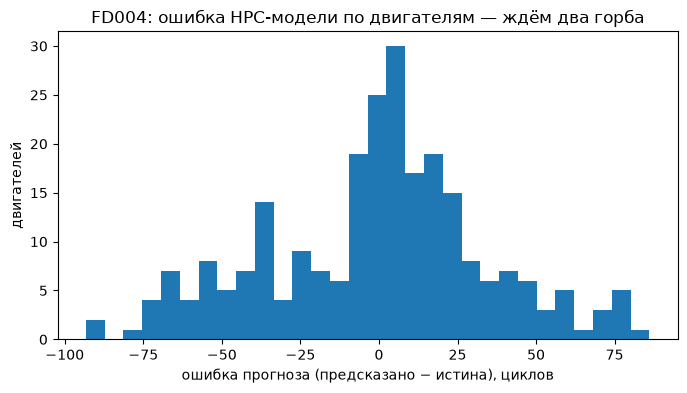

count    248.0
mean      -0.7
std       35.3
min      -93.3
25%      -24.7
50%        2.6
75%       19.6
max       86.1


In [ ]:
err4 = pd.Series(p_raw - rul4['RUL_true'].values)

plt.figure(figsize=(8, 4))
plt.hist(err4, bins=30)
plt.xlabel('ошибка прогноза (предсказано − истина), циклов')
plt.ylabel('двигателей')
plt.title('FD004: ошибка HPC-модели по двигателям — ждём два горба')
plt.show()

print(err4.describe().round(1).to_string())

Гипотеза бимодальности ошибки переноса (отдельные горба «свой/чужой»
тип отказа) не подтвердилась: распределение широкое, несмещённое
(mean −0.7, std 35.3), смешение по 2 типам × 12 условиям размывает
структуру. Тезис маршрутизатора опирается на цифры: native CV 17.93
против transfer 35.25.

In [ ]:
# потолок FD004: модель на своих данных, тот же протокол
train4['RUL'] = (train4.groupby('engine_id')['cycle'].transform('max')
                 - train4['cycle']).clip(upper=CONFIG['clip'])

sensors4 = [c for c in sensors2 if c in train4.columns]
gkf4 = GroupKFold(n_splits=5)
m4 = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                       num_leaves=31, random_state=CONFIG['random_state'],
                       verbose=-1)
s4 = -cross_val_score(m4, train4[sensors4], train4['RUL'],
                      groups=train4['engine_id'],
                      scoring='neg_root_mean_squared_error', cv=gkf4, n_jobs=-1)
print(f'FD004-native CV RMSE: {s4.mean():.2f} ± {s4.std():.2f}')

FD004-native CV RMSE: 17.93 ± 0.90


FD004-native CV: 17.93 ± 0.90 — лучший результат проекта, на самом сложном
наборе. Вывод, закрывший вопрос «улучшения модели»: смешанные отказы
неулучшимы предобработкой — они решаются покрытием данных. Модель
универсальна внутри своего покрытия и слепа вне его. Улучшать в модели
нечего: потолок ~18–20 одинаков на трёх наборах.

In [ ]:
# 1. z-нормировка train4 — тем же пайплайном
train4['alt'] = train4['os_1'].round(1)
train4['mach'] = train4['os_2'].round(2)
train4['thr_level'] = km_thr.predict(train4[['os_3']])
train4['regime'] = [pair_ids[(a, b)] for a, b in zip(train4['alt'], train4['mach'])]
train4['regime_full'] = train4['regime'] * 10 + train4['thr_level']

for s in sensors2:
    mu = train4['regime_full'].map(stats_mu[s])
    sd = train4['regime_full'].map(stats_sd[s])
    train4[f'{s}_z'] = ((train4[s] - mu) / sd).where(sd >= 1e-6, 0.0)

# 2. подпись двигателя: средний z по сенсорам на хвосте жизни (последние 50 циклов)
zcols4t = [f'{s}_z' for s in sensors2]
tail4 = train4[train4['RUL'] <= 50]
sig = tail4.groupby('engine_id')[zcols4t].mean()
print('матрица сигнатур:', sig.shape)

# 3. кластеризация двигателей
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(sig)
km2 = KMeans(n_clusters=2, random_state=42, n_init=10)
lab = pd.Series(km2.fit_predict(Xs), index=sig.index)
print('silhouette:', round(silhouette_score(Xs, lab), 3))

# 4. физическая проверка: какой кластер вентиляторный
fan = ['sensor_8_z', 'sensor_13_z', 'sensor_15_z']
core = ['sensor_7_z', 'sensor_9_z', 'sensor_12_z', 'sensor_14_z']
for c in (0, 1):
    m = lab == c
    print(f'кластер {c}: n={int(m.sum())}, '
          f'fan-z={sig.loc[m, fan].mean().mean():.2f}, '
          f'core-z={sig.loc[m, core].mean().mean():.2f}')

матрица сигнатур: (249, 20)
silhouette: 0.562
кластер 0: n=143, fan-z=2.23, core-z=-0.05
кластер 1: n=106, fan-z=1.53, core-z=7.57


In [ ]:
# per-cluster модели: out-of-fold прогноз по каждому кластеру
oof = pd.Series(index=train4.index, dtype=float)

for c in (0, 1):
    eng_c = sig.index[lab == c]
    dfc = train4[train4['engine_id'].isin(eng_c)]
    gkf = GroupKFold(n_splits=5)
    for tr, te in gkf.split(dfc, dfc['RUL'], dfc['engine_id']):
        m = lgb.LGBMRegressor(learning_rate=0.03, n_estimators=300,
                              num_leaves=31, random_state=CONFIG['random_state'],
                              verbose=-1)
        m.fit(dfc[sensors4].iloc[tr], dfc['RUL'].iloc[tr])
        oof.loc[dfc.index[te]] = m.predict(dfc[sensors4].iloc[te])

print('глобальная модель (CV): 17.93 ± 0.90')
print('per-cluster OOF RMSE:',
      round(np.sqrt(mean_squared_error(train4['RUL'], oof)), 2))

глобальная модель (CV): 17.93 ± 0.90
per-cluster OOF RMSE: 17.77


Per-cluster модели: OOF RMSE 17.77 против глобальной 17.93 — разница в шуме.
Маршрутизация бесплатна в точности (покрытие уже есть) и незаменима при
переносе: на незнакомой партии глобальная модель выдала бы 35.25, не
подозревая о проблеме, а маршрутизатор распознаёт тип и вешает флаг.

## Заключение

**Пять принципов, подтверждённых данными:**
1. Запас предупреждения без оценки ложных тревог не имеет смысла (версии B/C
   дали правдоподобные 194 и 167 циклов — и тревожили всех).
2. Сырые сенсоры + градиентный бустинг неулучшимы предобработкой
   (rolling-признаки и z-нормировка в домене — в пределах шума).
3. Предобработка критична для не-обучаемых компонентов: детектор на FD002
   ожил с 3.5% до 91% строго после z-нормировки, правило не менялось.
4. Модель универсальна внутри покрытия и слепа вне его (native ~18–20
   против transfer 26–50).
5. Сомнительные результаты проверять до записи, а не после: три бага
   (самотест на калибровке, дрожание ключей режимов, чужой RUL) пойманы
   показом сырых строк и сверкой с зафиксированными числами.

**Архитектура для k типов отказов:** детектор (типо-независимый) →
кластеризация сигнатур деградации (метки не нужны) → модель своего типа
→ флаг уверенности для незнакомого.

Статус: исследование завершено, код готовится к упаковке в единый пайплайн.